## Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Missing categorical values are replaced with a constant value and encoded using One-Hot Encoding (OHE). Numerical missing values are handled natively by XGBoost.
5. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
6. RandomizedSearchCV with 30 iterations and 5-Fold Stratified CV is used to tune XGBoost hyperparameters based on PR-AUC.
7. Regularization is controlled using max_depth, min_child_weight, gamma, reg_alpha, and reg_lambda, along with subsampling and column sampling.
8. The best model generates churn probabilities on the validation set.
9. A fine-grained threshold analysis (0.05–0.95) is performed to select the threshold with the highest F1 Score.
10. The selected threshold is applied to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
11. Model performance is evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
12. Diagnostic cross-validation is performed, and feature importance is analysed to identify the most influential features.

Exp 8(4) as took the best-performing XGBoost Classifier model from Exp4 and carried it forward as a new experiment under Exp8

In [1]:
# Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization

## 0. IMPORT LIBRARIES

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. SEPARATE FEATURES AND TARGET

In [4]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Total Missing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

Total Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 2. ORIGINAL TRAIN TEST SPLIT

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


## 3. INTERNAL TRAIN VALIDATION SPLIT

In [6]:
# Keep test data untouched.
# Use validation data only for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)


## 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS

In [7]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


## 5. CALCULATE CLASS IMBALANCE RATIO

In [8]:
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight_value)


==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123


## 6. PREPROCESSING PIPELINE

In [9]:
# XGBoost handles numerical missing values natively.
# Categorical missing values must be imputed before OneHotEncoder.

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

## 7. XGBOOST PIPELINE

In [10]:
xgb_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

## 8. STRATIFIED CROSS VALIDATION

In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 9. HYPERPARAMETER SEARCH SPACE

In [12]:
param_grid = {
    'model__n_estimators': [200, 300, 500, 700],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1, 1],
    'model__reg_lambda': [1, 3, 5, 10],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.5,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

## 10. RANDOMIZED SEARCH CV

In [13]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 11. FIT RANDOMIZED SEARCH

In [14]:
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.6, 0.7, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], ...}"
,n_iter,30
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 12. BEST HYPERPARAMETERS

In [15]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.8, 'model__scale_pos_weight': 1, 'model__reg_lambda': 1, 'model__reg_alpha': 0, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 0.8}

Best CV PR-AUC:
0.2841662008302841


## 13. BEST XGBOOST MODEL

In [16]:
best_xgb_pipeline = random_search.best_estimator_

## 14. RANDOMIZED SEARCH RESULTS

In [17]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__learning_rate',
        'param_model__subsample',
        'param_model__colsample_bytree',
        'param_model__min_child_weight',
        'param_model__scale_pos_weight',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_model__max_depth  param_model__learning_rate  param_model__subsample  param_model__colsample_bytree  param_model__min_child_weight  param_model__scale_pos_weight  mean_train_score  mean_test_score  std_test_score
                       700                       4                        0.05                     0.8                            0.8                              1                         1.0000            0.9801           0.2842          0.0268
                       500                       6                        0.10                     1.0                            1.0                              1                         6.9705            0.9994           0.2774          0.0360
                       500                       6                        0.03                     0.9                            1.0                              3                         4.6470            0.9938

## 15. VALIDATION PROBABILITIES

In [18]:
y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

## 16. PRECISION RECALL CURVE

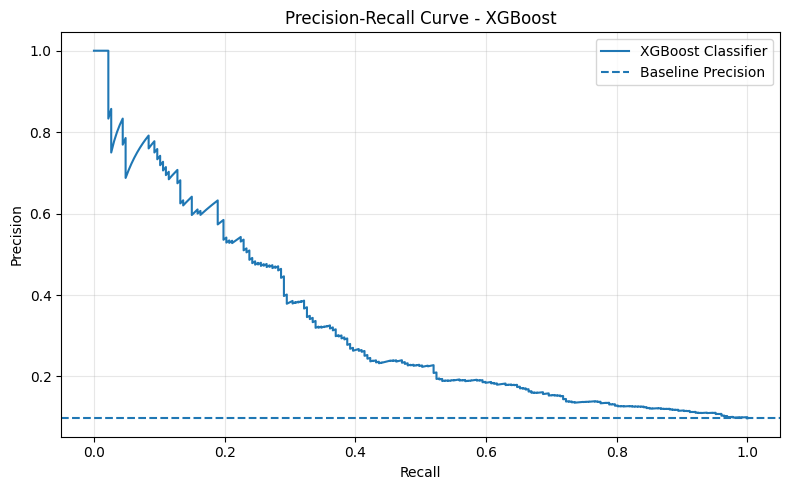

In [19]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='XGBoost Classifier'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 17. FINE-GRAINED THRESHOLD ANALYSIS

In [20]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1382  0.7269    0.2322
      0.06     0.1575  0.6960    0.2569
      0.07     0.1721  0.6520    0.2723
      0.08     0.1842  0.6079    0.2828
      0.09     0.1906  0.5330    0.2807
      0.10     0.2193  0.5198    0.3085
      0.11     0.2319  0.4802    0.3128
      0.12     0.2385  0.4581    0.3137
      0.13     0.2455  0.4229    0.3107
      0.14     0.2605  0.4097    0.3185
      0.15     0.2755  0.3921    0.3236
      0.16     0.2919  0.3833    0.3314
      0.17     0.3111  0.3700    0.3380
      0.18     0.3197  0.3436    0.3312
      0.19     0.3408  0.3348    0.3378
      0.20     0.3700  0.3260    0.3466
      0.21     0.3817  0.3128    0.3438
      0.22     0.3807  0.2952    0.3325
      0.23     0.4314  0.2907    0.3474
      0.24     0.4604  0.2819    0.3497
      0.25     0.4754  0.2555    0.3324
      0.26     0.5000  0.2379    0.3224
      0.27     0.5098  0.2291    0.31

## 18. THRESHOLD PERFORMANCE VISUALIZATION

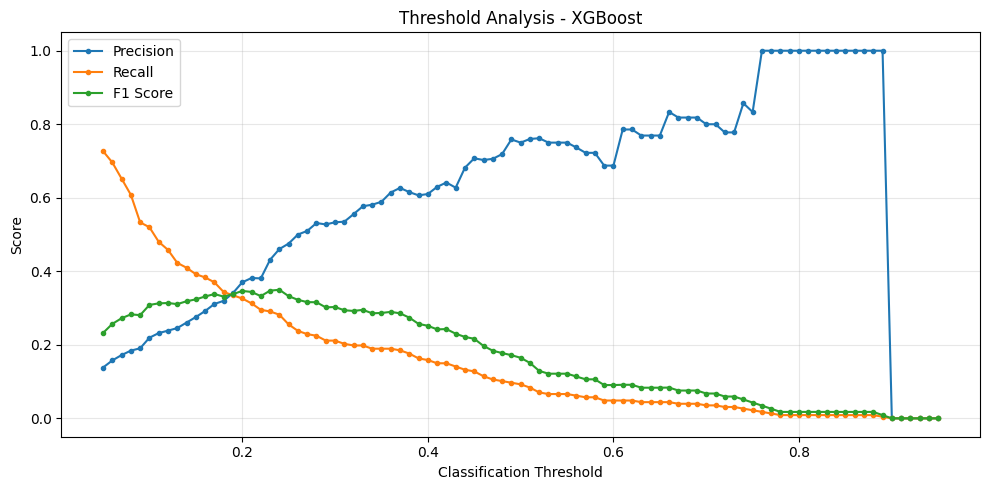

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 19. SELECT BEST THRESHOLD

In [22]:
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])


==== BEST THRESHOLD ====
Best Threshold: 0.24000000000000005
Threshold    0.240000
Precision    0.460432
Recall       0.281938
F1 Score     0.349727
Name: 19, dtype: float64


## 20. DEFINE METRIC FUNCTION

In [23]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 21. TRAINING PREDICTIONS

In [24]:
y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

## 22. VALIDATION PREDICTIONS

In [25]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

## 23. TEST PREDICTIONS

In [26]:
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

## 24. CALCULATE METRICS

In [27]:
train_metrics = calc_metrics(
    y_fit,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

## 25. PRINT TRAIN METRICS

In [28]:
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9790
Precision   : 0.9188
Recall      : 0.8601
F1 Score    : 0.8885
ROC-AUC     : 0.9927
PR-AUC      : 0.9555


## 26. PRINT VALIDATION METRICS

In [29]:
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8982
Precision   : 0.4604
Recall      : 0.2819
F1 Score    : 0.3497
ROC-AUC     : 0.7134
PR-AUC      : 0.3267


## 27. PRINT TEST METRICS

In [30]:
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8939
Precision   : 0.4309
Recall      : 0.2852
F1 Score    : 0.3432
ROC-AUC     : 0.6924
PR-AUC      : 0.3215


## 28. CONFUSION MATRIX

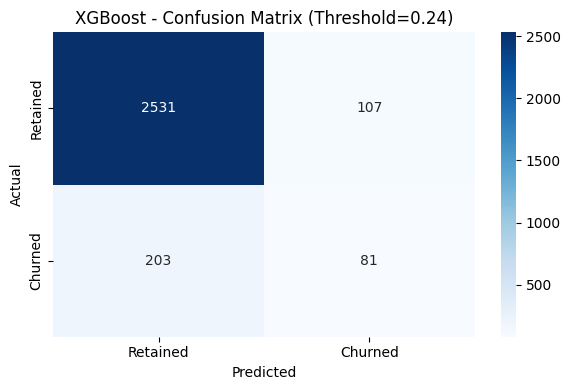

In [31]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'XGBoost - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

## 29. CLASSIFICATION REPORT

In [32]:
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.96      0.94      2638
     Churned       0.43      0.29      0.34       284

    accuracy                           0.89      2922
   macro avg       0.68      0.62      0.64      2922
weighted avg       0.88      0.89      0.88      2922



## 30. CROSS VALIDATION PERFORMANCE

In [33]:
# Diagnostic CV scores for the selected model.
# These are not an independent estimate after hyperparameter selection.

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

## 31. CROSS VALIDATION TRAIN SCORES

In [34]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9600, Std: 0.0014
train_Precision - Mean: 0.9991, Std: 0.0011
train_Recall - Mean: 0.5884, Std: 0.0150
train_F1 - Mean: 0.7405, Std: 0.0119
train_ROC_AUC - Mean: 0.9971, Std: 0.0003
train_PR_AUC - Mean: 0.9801, Std: 0.0014


## 32. CROSS VALIDATION VALIDATION SCORES

In [35]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9072, Std: 0.0031
test_Precision - Mean: 0.6640, Std: 0.1115
test_Recall - Mean: 0.0881, Std: 0.0230
test_F1 - Mean: 0.1553, Std: 0.0383
test_ROC_AUC - Mean: 0.6838, Std: 0.0231
test_PR_AUC - Mean: 0.2842, Std: 0.0268


## 33. FEATURE IMPORTANCE

In [36]:
xgb_model = best_xgb_pipeline.named_steps['model']

feature_names = (
    best_xgb_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))


==== TOP 20 IMPORTANT FEATURES ====
                                       Feature  Importance
    origin_up_lxidpiddsbxsbosboudacockeimpuepw    0.019440
    origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws    0.019388
                     peak_offpeak_fix_relative    0.018812
              discount_consumption_interaction    0.017839
                     dec_jan_mid_peak_fix_diff    0.016895
                      forecast_discount_energy    0.016821
                                 renewal_month    0.013621
                                    price_peak    0.013382
                        mean_year_mid_peak_fix    0.013248
                                        tenure    0.013192
                            margin_net_pow_ele    0.012701
channel_sales_lmkebamcaaclubfxadlmueccxoimlema    0.012448
                         dec_jan_peak_fix_diff    0.012401
                           var_year_price_peak    0.012174
                              margin_per_power    0.011537
                   

## 34. FEATURE IMPORTANCE VISUALIZATION

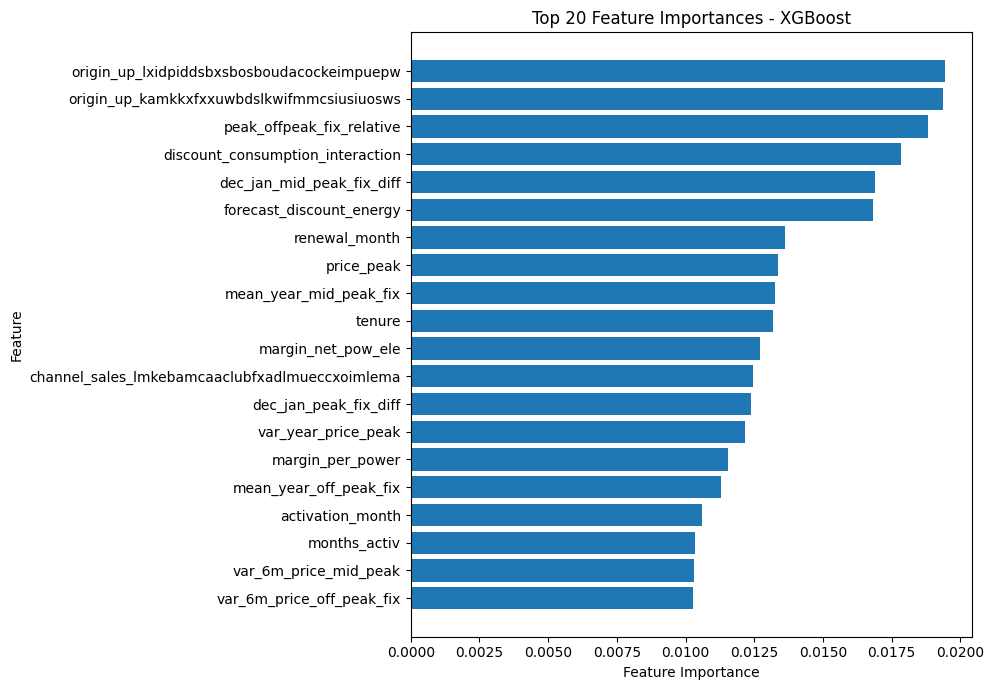

In [37]:
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - XGBoost')
plt.tight_layout()
plt.show()

# **Observation: Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 30 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 700
  - `max_depth`: 4
  - `learning_rate`: 0.05
  - `subsample`: 0.8
  - `colsample_bytree`: 0.8
  - `min_child_weight`: 1
  - `gamma`: 0.1
  - `reg_alpha`: 0
  - `reg_lambda`: 1
  - `scale_pos_weight`: 1
- Best CV PR-AUC: **28.42%**

**Observation:**

- Selected a relatively shallow tree depth of 4 to control model complexity.
- CV PR-AUC improved compared to Exp5 (26.38%) but remained lower than Exp2 (30.55%).
- Training performance remains extremely high, indicating overfitting.
- Hyperparameter tuning did not provide a substantial improvement in validation performance.

**2. Model Performance – Test Data**

- Accuracy: **89.39%**
- Precision: **43.09%**
- Recall: **28.52%**
- F1 Score: **34.32%**
- ROC-AUC: **69.24%**
- PR-AUC: **32.15%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.24**, based on the highest F1 score in the threshold analysis.
- At threshold 0.24 (threshold validation):
  - Precision: 46.04%
  - Recall: 28.19%
  - F1 Score: 34.97%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.
- Threshold 0.24 provides a reasonable balance between precision and recall.

**4. Confusion Matrix (Threshold = 0.24)**

- True Negatives: 2,531
- False Positives: 107
- False Negatives: 203
- True Positives: 81

**Observation:**

- Model correctly identifies 81 churn customers out of 284.
- It misses 203 actual churn customers.
- False positives are relatively low (107).
- However, the model fails to identify a large proportion of actual churn customers.
- The model prioritizes precision over recall.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.15% indicates better performance than the baseline.
- However, PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).

**6. Cross-Validation Results**

- Training PR-AUC: 98.01%
- Validation accuracy: 90.72%
- Validation precision: 66.40%
- Validation recall: 8.81%
- Validation F1: 15.53%
- Validation ROC-AUC: 68.38%
- Validation PR-AUC: 28.42%

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Validation recall is extremely low at the default 0.50 threshold.
- Validation precision is high, but the model identifies very few churn customers.
- Despite high training performance, generalization to validation data remains limited.

**7. Top 20 Important Features**

The most important features include:

- origin_up_lxidpiddsbxsbosboudacockeimpuepw
- origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws
- peak_offpeak_fix_relative
- discount_consumption_interaction
- dec_jan_mid_peak_fix_diff
- forecast_discount_energy
- renewal_month
- price_peak
- mean_year_mid_peak_fix
- tenure
- margin_net_pow_ele
- channel_sales_lmkebamcaaclubfxadlmueccxoimlema
- dec_jan_peak_fix_diff
- var_year_price_peak
- margin_per_power

**Observation:**

- Price-related, discount-related and consumption-related features contribute significantly.
- Customer subscription information (`origin_up`) appears among the most important features.
- Tenure and renewal-related features also contribute to churn prediction.
- Feature importance patterns indicate that pricing behaviour and customer characteristics are important for identifying churn.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF | Exp8(4)-XGB |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- | ---------- | ----------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   | 82.07%     | **89.39%**  |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   | 25.71%     | **43.09%**  |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        | 34.86%   | **44.72%** | 28.52%      |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   | 32.65%     | 34.32%      |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   | 69.98%     | 69.24%      |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   | 34.26%     | 32.15%      |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   | 27.35%     | 28.42%      |

**Observation:**

- Exp8(4) achieves the highest accuracy (89.39%), tied with Exp4.
- Precision (43.09%) is also the highest, tied with Exp4.
- However, recall is relatively low at 28.52%.
- PR-AUC (32.15%) is lower than Exp2 and Exp8(2).
- Exp8(2) achieves considerably higher recall (44.72%).
- Exp2 maintains the highest PR-AUC (35.75%) and F1 Score (34.86%).
- Exp8(4) is more conservative in identifying churn customers, resulting in fewer false positives but more missed churn customers.

**Final Conclusion – Exp 8(4) XGBoost**

- Achieves a test PR-AUC of 32.15%.
- Achieves high precision of 43.09%.
- Correctly identifies 81 churn customers out of 284.
- Generates only 107 false positives.
- However, it misses 203 actual churn customers.
- Significant overfitting remains a concern.
- The model does not improve overall churn prediction performance compared to the existing best models.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), providing a better balance between precision and recall.

Exp8(2) is a strong alternative when identifying more churn customers is the priority, achieving the highest recall (44.72%).

Exp8(4) is more suitable when controlling false positives and maintaining higher precision are priorities.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.24 threshold. Compare classification metrics cautiously.

**One thing to verify:** Exp8(4) has exactly the same test accuracy, precision, recall, F1, ROC-AUC and PR-AUC as Exp4. This suggests the two experiments may have reproduced the same test predictions or evaluation results. Hence not conside this Exp8(4) result here onwards